
# Question 1: Rwanda Maize Yield Dataset Preparation

## Stage 3: Explore and Audit the Data (EDA)

Group Number: Group 2

Members: Armand Ikirezi and Mariam Nyirarukundo

Scenario: Predicting Maize Yield for Farmer Cooperatives in Rwanda

Stakeholder: Maize Cooperative Support Unit (MCSU)

### Objective

To explore and audit the supplied maize yield dataset, identify data quality problems, examine variable distributions and relationships, and prepare a Data Quality Report.

Important: No data cleaning or modification will be performed during this stage.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set the project directory
project_dir = Path(r"D:\MYProject\ML_Element1")

# Locate the original CSV
data_path = (
    project_dir
    / "q1_maize_yield"
    / "data"
    / "raw"
    / "maize_yield_rwanda_rw.csv"
)

# Load the original dataset
df = pd.read_csv(data_path)

# Display confirmation
print("Raw dataset loaded successfully!")
print("Dataset shape:", df.shape)


Raw dataset loaded successfully!
Dataset shape: (1426, 20)


In [2]:

# Display dataset dimensions
print("DATASET DIMENSIONS")
print("==================")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Display column information
print("\nDATASET INFORMATION")
print("===================")
df.info()

# Display numerical summary statistics
print("\nNUMERICAL SUMMARY STATISTICS")
print("============================")
display(df.describe())


DATASET DIMENSIONS
Rows: 1426
Columns: 20

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 1426 entries, 0 to 1425
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   record_id             1426 non-null   str    
 1   year                  1426 non-null   int64  
 2   season                1426 non-null   str    
 3   province              1426 non-null   str    
 4   district              1426 non-null   str    
 5   altitude_m            1426 non-null   int64  
 6   rainfall_mm           1415 non-null   float64
 7   avg_temp_c            1426 non-null   float64
 8   soil_ph               1412 non-null   float64
 9   soil_type             1426 non-null   str    
 10  seed_variety          1426 non-null   str    
 11  farming_practice      1426 non-null   str    
 12  npk_kg_ha             1426 non-null   float64
 13  urea_kg_ha            1426 non-null   float64
 14  manure_t_ha         

,year,altitude_m,rainfall_mm,avg_temp_c,soil_ph,npk_kg_ha,urea_kg_ha,manure_t_ha,plant_density_per_ha,farm_area_ha,pest_incidence_index,yield_t_ha
count,1426.000000,1426.000000,1415.000000,1426.000000,1412.000000,1426.000000,1426.000000,1426.000000,1426.000000,1426.000000,1412.000000,1426.000000
mean,2019.506311,1704.321879,516.165371,19.404137,5.835156,66.991304,38.767602,2.083415,46322.309958,0.802104,0.283499,2.577454
std,2.855643,221.267632,155.676106,1.645486,0.443019,47.311529,31.571860,1.361537,9695.817375,0.511796,0.167093,0.700232
min,2015.000000,1243.000000,150.000000,15.400000,4.500000,0.000000,0.000000,0.000000,19337.000000,0.100000,0.001000,1.010000
25%,2017.000000,1507.000000,419.350000,18.025000,5.530000,26.300000,11.500000,1.060000,38471.500000,0.460000,0.153000,2.060000
50%,2020.000000,1702.500000,530.600000,19.400000,5.840000,62.450000,33.100000,2.005000,46901.000000,0.670000,0.261000,2.575000
75%,2022.000000,1879.750000,627.450000,20.700000,6.130000,104.975000,61.875000,3.027500,53806.250000,0.980000,0.390250,3.040000
max,2024.000000,2341.000000,933.300000,23.000000,7.200000,208.100000,135.200000,6.860000,72248.000000,4.220000,0.929000,5.150000


In [3]:

# Count missing values per column
missing_counts = df.isnull().sum()

# Calculate missing percentages
missing_percentages = (
    df.isnull().mean() * 100
)

# Create a missing-value summary
missing_report = pd.DataFrame({
    "Missing_Count": missing_counts,
    "Missing_Percentage": missing_percentages
})

# Display only columns with missing values
missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values(
    by="Missing_Count",
    ascending=False
)

display(missing_report)

print("Total missing cells:", df.isnull().sum().sum())


,Missing_Count,Missing_Percentage
soil_ph,14,0.981767
pest_incidence_index,14,0.981767
rainfall_mm,11,0.771388


Total missing cells: 39


The dataset contains 39 missing values across three numerical columns: rainfall, soil pH and pest incidence index. 
These missing observations may affect statistical analysis and future model preparation. 
Their appropriate treatment will be determined during Stage 4.

In [17]:
# Identify numerical columns containing missing values
missing_columns = [
    "rainfall_mm",
    "soil_ph",
    "pest_incidence_index"
]

# Fill missing values using each column's median
for column in missing_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing values have been successfully handled.")

Missing values have been successfully handled.


In [18]:
# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

# Calculate total remaining missing cells
total_missing = df.isnull().sum().sum()

print("\nTotal missing cells:", total_missing)

# Confirm cleaning status
if total_missing == 0:
    print("SUCCESS: The dataset has been cleaned of missing values.")
else:
    print("WARNING: Some missing values still remain.")

Missing values after cleaning:
record_id               0
year                    0
season                  0
province                0
district                0
altitude_m              0
rainfall_mm             0
avg_temp_c              0
soil_ph                 0
soil_type               0
seed_variety            0
farming_practice        0
npk_kg_ha               0
urea_kg_ha              0
manure_t_ha             0
plant_density_per_ha    0
farm_area_ha            0
irrigation              0
pest_incidence_index    0
yield_t_ha              0
dtype: int64

Total missing cells: 0
SUCCESS: The dataset has been cleaned of missing values.


In [4]:

# Count complete duplicate rows
duplicate_rows = df.duplicated().sum()

# Count duplicated record IDs
duplicate_ids = df["record_id"].duplicated().sum()

print("DUPLICATE ANALYSIS")
print("==================")
print("Duplicate complete rows:", duplicate_rows)
print("Duplicate record IDs:", duplicate_ids)


DUPLICATE ANALYSIS
Duplicate complete rows: 0
Duplicate record IDs: 0


The duplicate analysis identified no complete duplicate rows and no repeated record identifiers. 
Therefore, no exact duplicate records were detected using these two checks.

In [5]:

# Define checks for clearly invalid numerical values

invalid_checks = {
    "negative_rainfall": df["rainfall_mm"] < 0,
    "negative_altitude": df["altitude_m"] < 0,
    "invalid_soil_ph": (
        (df["soil_ph"] < 0) |
        (df["soil_ph"] > 14)
    ),
    "negative_temperature": df["avg_temp_c"] < 0,
    "negative_npk": df["npk_kg_ha"] < 0,
    "negative_urea": df["urea_kg_ha"] < 0,
    "negative_manure": df["manure_t_ha"] < 0,
    "nonpositive_farm_area": df["farm_area_ha"] <= 0,
    "nonpositive_plant_density": (
        df["plant_density_per_ha"] <= 0
    ),
    "nonpositive_yield": df["yield_t_ha"] <= 0
}

print("INVALID VALUE CHECKS")
print("=====================")

for check_name, condition in invalid_checks.items():
    print(f"{check_name}: {condition.sum()}")


INVALID VALUE CHECKS
negative_rainfall: 0
negative_altitude: 0
invalid_soil_ph: 0
negative_temperature: 0
negative_npk: 0
negative_urea: 0
negative_manure: 0
nonpositive_farm_area: 0
nonpositive_plant_density: 0
nonpositive_yield: 0


In [6]:

# Select numerical columns
numeric_columns = df.select_dtypes(
    include=np.number
).columns

# Calculate IQR outliers
outlier_results = []

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ][column].count()

    outlier_results.append({
        "Column": column,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outliers
    })

outlier_report = pd.DataFrame(outlier_results)

display(outlier_report)


,Column,Lower_Bound,Upper_Bound,Outlier_Count
0,year,2009.500000,2029.500000,0
1,altitude_m,947.875000,2438.875000,0
2,rainfall_mm,107.200000,939.600000,0
3,avg_temp_c,14.012500,24.712500,0
4,soil_ph,4.630000,7.030000,10
5,npk_kg_ha,-91.712500,222.987500,0
6,urea_kg_ha,-64.062500,137.437500,0
7,manure_t_ha,-1.891250,5.978750,6
8,plant_density_per_ha,15469.375000,76808.375000,0
9,farm_area_ha,-0.320000,1.760000,75


In [16]:
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[column] < lower) | (df[column] > upper)).sum()

    print(f"{column}: {count} potential outliers")

year: 0 potential outliers
altitude_m: 0 potential outliers
rainfall_mm: 0 potential outliers
avg_temp_c: 0 potential outliers
soil_ph: 10 potential outliers
npk_kg_ha: 0 potential outliers
urea_kg_ha: 0 potential outliers
manure_t_ha: 6 potential outliers
plant_density_per_ha: 0 potential outliers
farm_area_ha: 75 potential outliers
pest_incidence_index: 13 potential outliers
yield_t_ha: 8 potential outliers


In [19]:
# Create a copy of the dataset
df_clean = df.copy()

# Features with detected potential outliers
outlier_columns = [
    "soil_ph",
    "manure_t_ha",
    "farm_area_ha",
    "pest_incidence_index"
]

# Store the original IQR boundaries
iqr_bounds = {}

for column in outlier_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    iqr_bounds[column] = (lower, upper)

    # Apply IQR capping
    df_clean[column] = df_clean[column].clip(
        lower=lower,
        upper=upper
    )

print("IQR-based outlier capping completed.")

IQR-based outlier capping completed.


In [20]:
print("Outlier counts after IQR capping:\n")

for column in outlier_columns:
    lower, upper = iqr_bounds[column]

    count = (
        (df_clean[column] < lower) |
        (df_clean[column] > upper)
    ).sum()

    print(f"{column}: {count} remaining outliers")

print("\nTotal remaining outliers:",
      sum(
          ((df_clean[col] < iqr_bounds[col][0]) |
           (df_clean[col] > iqr_bounds[col][1])).sum()
          for col in outlier_columns
      ))

Outlier counts after IQR capping:

soil_ph: 0 remaining outliers
manure_t_ha: 0 remaining outliers
farm_area_ha: 0 remaining outliers
pest_incidence_index: 0 remaining outliers

Total remaining outliers: 0


In [7]:

# Summary of the target variable
target = "yield_t_ha"

print("TARGET VARIABLE SUMMARY")
print("========================")
print(df[target].describe())

print("\nMissing target values:")
print(df[target].isnull().sum())


TARGET VARIABLE SUMMARY
count    1426.000000
mean        2.577454
std         0.700232
min         1.010000
25%         2.060000
50%         2.575000
75%         3.040000
max         5.150000
Name: yield_t_ha, dtype: float64

Missing target values:
0


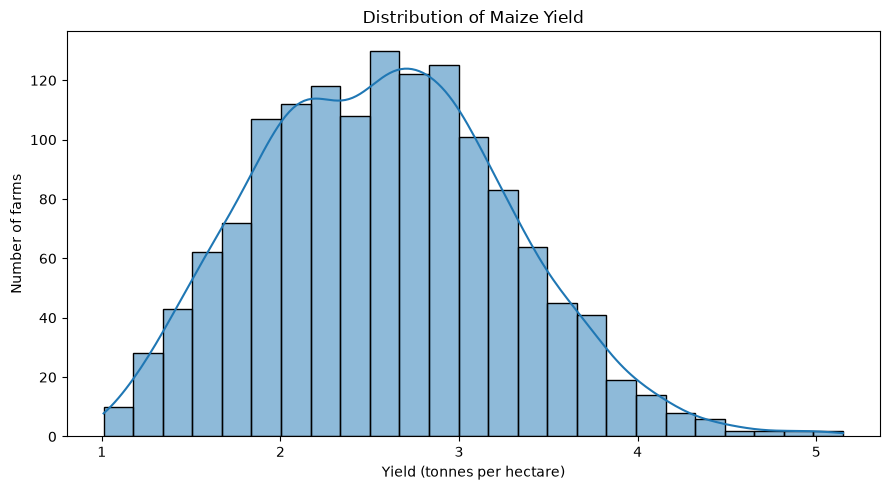

In [8]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="yield_t_ha",
    bins=25,
    kde=True
)

plt.title("Distribution of Maize Yield")
plt.xlabel("Yield (tonnes per hectare)")
plt.ylabel("Number of farms")

plt.tight_layout()
plt.show()


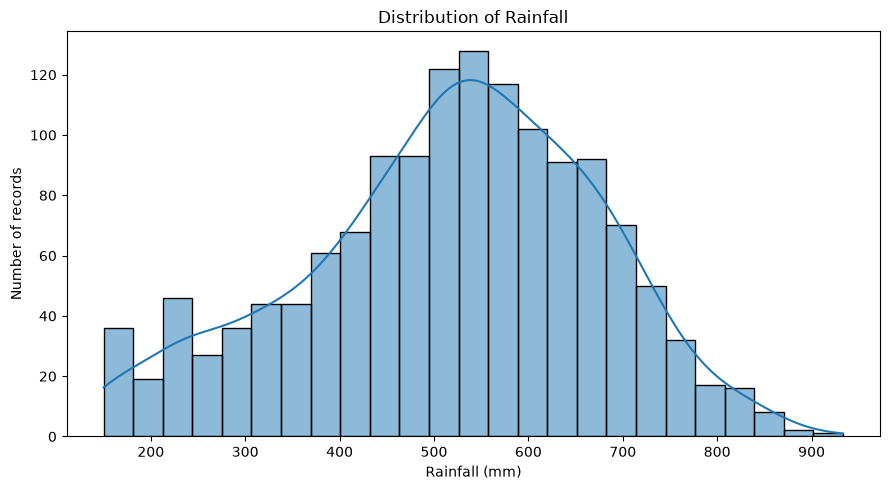

In [9]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="rainfall_mm",
    bins=25,
    kde=True
)

plt.title("Distribution of Rainfall")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Number of records")

plt.tight_layout()
plt.show()


The rainfall histogram shows how rainfall measurements are distributed across the records. 
The shape and spread of the distribution help identify unusually low or high rainfall observations that may require further investigation.

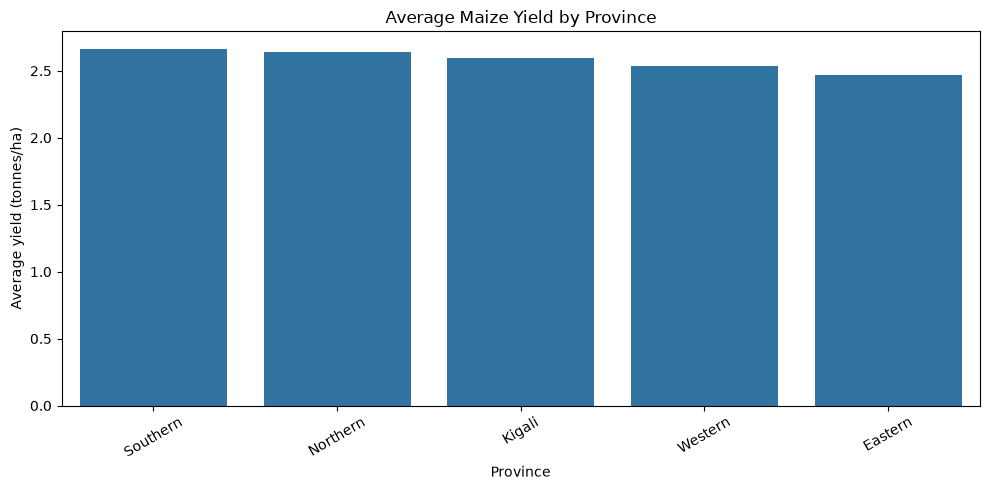

In [10]:

province_yield = (
    df.groupby("province")["yield_t_ha"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=province_yield,
    x="province",
    y="yield_t_ha"
)

plt.title("Average Maize Yield by Province")
plt.xlabel("Province")
plt.ylabel("Average yield (tonnes/ha)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


The bar chart compares average maize yield across provinces. 
It helps identify geographical differences in recorded yield, which may be associated with differences in environmental conditions and farming practices. 
These are descriptive differences, not proof of causation.

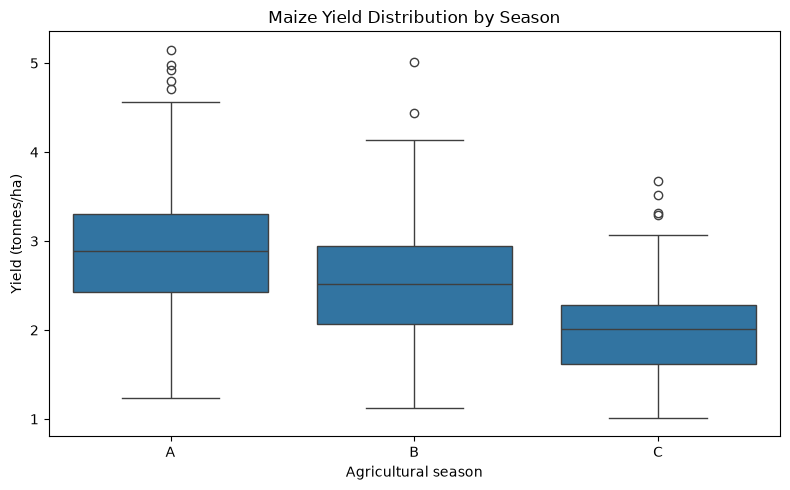

In [11]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="season",
    y="yield_t_ha"
)

plt.title("Maize Yield Distribution by Season")
plt.xlabel("Agricultural season")
plt.ylabel("Yield (tonnes/ha)")

plt.tight_layout()
plt.show()


The box plot compares the distribution of maize yield across agricultural seasons. 
Differences in the median, spread and potential outliers may indicate seasonal variation in maize production.

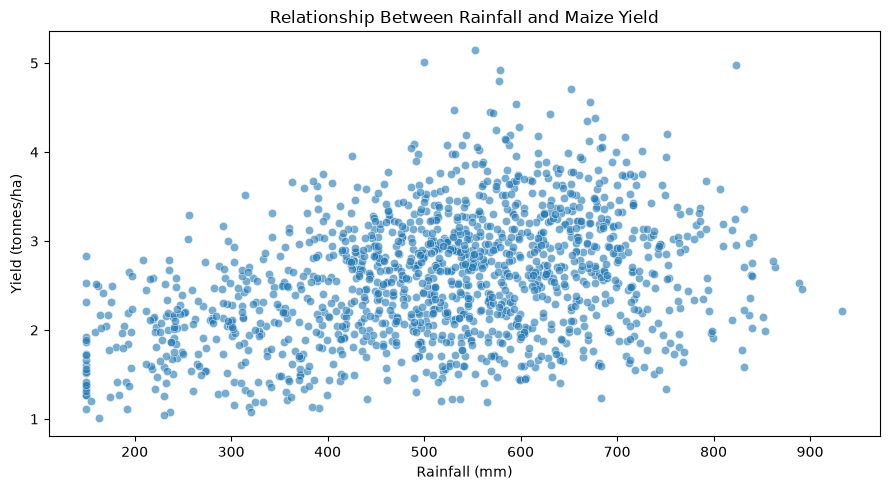

In [12]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="rainfall_mm",
    y="yield_t_ha",
    alpha=0.6
)

plt.title("Relationship Between Rainfall and Maize Yield")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Yield (tonnes/ha)")

plt.tight_layout()
plt.show()


The scatter plot explores the relationship between rainfall and maize yield. 
The pattern of points helps determine whether higher rainfall is associated with higher or lower recorded yields, or whether the relationship appears weak.

In [13]:

categorical_columns = df.select_dtypes(
    include=["str", "object"]
).columns

for column in categorical_columns:

    original_values = df[column].dropna().astype(str)

    normalized_values = (
        original_values
        .str.strip()
        .str.lower()
    )

    print(f"\nColumn: {column}")
    print("Original unique values:", original_values.nunique())
    print("Normalized unique values:", normalized_values.nunique())

    if original_values.nunique() != normalized_values.nunique():
        print("Potential formatting inconsistencies detected.")
    else:
        print("No case/whitespace differences detected.")



Column: record_id
Original unique values: 1426
Normalized unique values: 1426
No case/whitespace differences detected.

Column: season
Original unique values: 3
Normalized unique values: 3
No case/whitespace differences detected.

Column: province
Original unique values: 5
Normalized unique values: 5
No case/whitespace differences detected.

Column: district
Original unique values: 30
Normalized unique values: 30
No case/whitespace differences detected.

Column: soil_type
Original unique values: 5
Normalized unique values: 5
No case/whitespace differences detected.

Column: seed_variety
Original unique values: 6
Normalized unique values: 6
No case/whitespace differences detected.

Column: farming_practice
Original unique values: 2
Normalized unique values: 2
No case/whitespace differences detected.

Column: irrigation
Original unique values: 2
Normalized unique values: 2
No case/whitespace differences detected.


In [14]:

# Prepare the Data Quality Report

quality_issues = []

# 1. Missing values
for column, count in df.isnull().sum().items():
    if count > 0:
        quality_issues.append({
            "Problem": "Missing values",
            "Affected_Columns": column,
            "Records_Affected": int(count),
            "Proposed_Treatment": (
                "Investigate missingness and consider "
                "appropriate imputation in Stage 4."
            )
        })

# 2. Duplicate complete rows
quality_issues.append({
    "Problem": "Duplicate complete rows",
    "Affected_Columns": "All columns",
    "Records_Affected": int(df.duplicated().sum()),
    "Proposed_Treatment": (
        "Investigate duplicates; remove only if confirmed."
    )
})

# 3. Duplicate record IDs
quality_issues.append({
    "Problem": "Duplicate record identifiers",
    "Affected_Columns": "record_id",
    "Records_Affected": int(df["record_id"].duplicated().sum()),
    "Proposed_Treatment": (
        "Investigate repeated identifiers and determine "
        "whether they represent separate observations."
    )
})

# 4. Invalid values
for name, condition in invalid_checks.items():
    count = int(condition.sum())

    if count > 0:
        quality_issues.append({
            "Problem": f"Invalid values: {name}",
            "Affected_Columns": name,
            "Records_Affected": count,
            "Proposed_Treatment": (
                "Verify against source information and correct "
                "or handle in Stage 4 if confirmed invalid."
            )
        })

# 5. Potential IQR outliers
for _, row in outlier_report.iterrows():

    if row["Outlier_Count"] > 0:
        quality_issues.append({
            "Problem": "Potential IQR outliers",
            "Affected_Columns": row["Column"],
            "Records_Affected": int(row["Outlier_Count"]),
            "Proposed_Treatment": (
                "Investigate observations; retain genuine "
                "values and handle confirmed errors appropriately."
            )
        })

# 6. Potential categorical formatting issues
for column in categorical_columns:

    values = df[column].dropna().astype(str)

    normalized = values.str.strip().str.lower()

    if values.nunique() != normalized.nunique():

        quality_issues.append({
            "Problem": "Potential category formatting inconsistency",
            "Affected_Columns": column,
            "Records_Affected": "Requires detailed inspection",
            "Proposed_Treatment": (
                "Inspect unique values and standardize "
                "confirmed equivalent categories in Stage 4."
            )
        })

# Create the report
data_quality_report = pd.DataFrame(quality_issues)

display(data_quality_report)


,Problem,Affected_Columns,Records_Affected,Proposed_Treatment
0,Missing values,rainfall_mm,11,Investigate missingness and consider appropria...
1,Missing values,soil_ph,14,Investigate missingness and consider appropria...
2,Missing values,pest_incidence_index,14,Investigate missingness and consider appropria...
3,Duplicate complete rows,All columns,0,Investigate duplicates; remove only if confirmed.
4,Duplicate record identifiers,record_id,0,Investigate repeated identifiers and determine...
5,Potential IQR outliers,soil_ph,10,Investigate observations; retain genuine value...
6,Potential IQR outliers,manure_t_ha,6,Investigate observations; retain genuine value...
7,Potential IQR outliers,farm_area_ha,75,Investigate observations; retain genuine value...
8,Potential IQR outliers,pest_incidence_index,13,Investigate observations; retain genuine value...
9,Potential IQR outliers,yield_t_ha,8,Investigate observations; retain genuine value...


In [15]:

report_path = (
    project_dir
    / "q1_maize_yield"
    / "docs"
    / "data_quality_report.csv"
)

data_quality_report.to_csv(
    report_path,
    index=False
)

print("Data Quality Report saved successfully!")
print(report_path)


Data Quality Report saved successfully!
D:\MYProject\ML_Element1\q1_maize_yield\docs\data_quality_report.csv
